# Исследование и обучение моделей классификации (CyberGuard)

Цель работы:
1. Подготовить единый конвейер предобработки признаков без утечки данных.
2. Провести эксперименты с параметрами для моделей Logistic Regression, KNN и MLP на валидационной выборке.
3. Сравнить модели на независимом наборе `kdd_test.csv` по метрикам `Accuracy`, `Precision`, `Recall`, `F1-score` (для класса `Attack`) и матрице ошибок.

In [17]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

current_dir = Path.cwd()
project_root = current_dir.parent if current_dir.name == 'notebooks' else current_dir

raw_dir = project_root / 'data' / 'raw'
processed_dir = project_root / 'data' / 'processed'
processed_dir.mkdir(parents=True, exist_ok=True)

In [18]:
def split_features_and_target(df):
    # Нормальный трафик переводим в 0, любую атаку в 1
    y = (df['labels'].astype(str).str.strip().str.lower() != 'normal').astype(int)
    X = df.drop(columns=['labels'])
    return  X,y

df_train_raw = pd.read_csv(raw_dir / 'kdd_train.csv')
df_test_raw = pd.read_csv(raw_dir / 'kdd_test.csv')

X_full_train, y_full_train = split_features_and_target(df_train_raw)
X_test, y_test = split_features_and_target(df_test_raw)

# Выделяем 20% из обучающей выборки для подбора параметров, чтобы не подглядывать в kdd_test.csv
X_tr, X_val, y_tr, y_val = train_test_split(
    X_full_train,
    y_full_train,
    test_size=0.2,
    random_state=42,
    stratify=y_full_train
)

print('Обучение (X_tr):', X_tr.shape, '| Доля атак:', round(y_tr.mean() * 100, 2), '%')
print('Валидация (X_val):', X_val.shape, '| Доля атак:', round(y_val.mean() * 100, 2), '%')
print('Независимый тест (X_test):', X_test.shape, '| Доля атак:', round(y_test.mean() * 100, 2), '%')
print('Столбец labels отсутствует в X:', 'labels' not in X_tr.columns)

Обучение (X_tr): (100778, 41) | Доля атак: 46.54 %
Валидация (X_val): (25195, 41) | Доля атак: 46.54 %
Независимый тест (X_test): (22544, 41) | Доля атак: 50.12 %
Столбец labels отсутствует в X: True


In [19]:
# Фиксируем списки столбцов по результатам EDA
dropped_cols = ['num_outbound_cmds']
categorical_cols = ['protocol_type', 'service', 'flag']
numeric_cols = [
    col for col in X_full_train.columns
    if col not in dropped_cols and col not in categorical_cols
]


def make_preprocessor(scaler_name='standard'):
    if scaler_name == 'robust':
        scaler = RobustScaler()
    else:
        scaler = StandardScaler()

    # Удаляем константный столбец, масштабируем числа и кодируем категории внутри одного блока
    preprocessor = ColumnTransformer(
        transformers=[
            ('drop_const', 'drop', dropped_cols),
            ('num', scaler, numeric_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
        ]
    )
    return preprocessor


def evaluate_model(model, X_data, y_true):
    start_time = time.time()
    y_pred = model.predict(X_data)
    pred_seconds = round(time.time() - start_time, 2)

    metrics = {
        'Accuracy': round(accuracy_score(y_true, y_pred), 4),
        'Precision (Attack)': round(precision_score(y_true, y_pred, pos_label=1), 4),
        'Recall (Attack)': round(recall_score(y_true, y_pred, pos_label=1), 4),
        'F1-score (Attack)': round(f1_score(y_true, y_pred, pos_label=1), 4),
        'Время оценки (с)': pred_seconds
    }
    cm = confusion_matrix(y_true, y_pred)
    return metrics, cm

In [20]:
scaler_results = []

for scaler_name in ['standard', 'robust']:
    pipe = Pipeline([
        ('prep', make_preprocessor(scaler_name)),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ])
    pipe.fit(X_tr, y_tr)
    metrics, _ = evaluate_model(pipe, X_val, y_val)
    metrics['Скейлер'] = scaler_name
    scaler_results.append(metrics)

df_scaler_exp = pd.DataFrame(scaler_results).set_index('Скейлер')
print('Сравнение скейлеров на валидации (Logistic Regression):')
df_scaler_exp

Сравнение скейлеров на валидации (Logistic Regression):


C:\Users\nevoll\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Accuracy,Precision (Attack),Recall (Attack),F1-score (Attack),Время оценки (с)
Скейлер,,,,,
standard,0.9719,0.9763,0.9630,0.9696,0.08
robust,0.9623,0.9623,0.9565,0.9594,0.09


In [21]:
# Укажи здесь лучший скейлер по итогам ячейки 5 (обычно 'standard')
best_scaler = 'standard'

logreg_results = []
for c_value in [0.1, 1.0, 10.0]:
    pipe = Pipeline([
        ('prep', make_preprocessor(best_scaler)),
        ('clf', LogisticRegression(C=c_value, max_iter=1000, random_state=42))
    ])
    pipe.fit(X_tr, y_tr)
    metrics, _ = evaluate_model(pipe, X_val, y_val)
    metrics['C'] = c_value
    logreg_results.append(metrics)

df_logreg_exp = pd.DataFrame(logreg_results).set_index('C')
print('Подбор C для Logistic Regression (валидация):')
df_logreg_exp

Подбор C для Logistic Regression (валидация):


,Accuracy,Precision (Attack),Recall (Attack),F1-score (Attack),Время оценки (с)
C,,,,,
0.1,0.9696,0.9758,0.9585,0.9670,0.07
1.0,0.9719,0.9763,0.9630,0.9696,0.09
10.0,0.9726,0.9767,0.9642,0.9704,0.12


In [22]:
knn_results = []

for k_value in [3, 5, 9]:
    pipe = Pipeline([
        ('prep', make_preprocessor(best_scaler)),
        ('clf', KNeighborsClassifier(n_neighbors=k_value, n_jobs=-1))
    ])
    pipe.fit(X_tr, y_tr)
    metrics, _ = evaluate_model(pipe, X_val, y_val)
    metrics['n_neighbors'] = k_value
    knn_results.append(metrics)

df_knn_exp = pd.DataFrame(knn_results).set_index('n_neighbors')
print('Подбор числа соседей для KNN (валидация):')
df_knn_exp

Подбор числа соседей для KNN (валидация):


,Accuracy,Precision (Attack),Recall (Attack),F1-score (Attack),Время оценки (с)
n_neighbors,,,,,
3,0.9971,0.9977,0.9961,0.9969,8.63
5,0.9969,0.9971,0.9962,0.9967,8.25
9,0.9957,0.9964,0.9944,0.9954,7.79


In [23]:
mlp_results = []

for layers in [(64,), (64, 32), (128, 64)]:
    pipe = Pipeline([
        ('prep', make_preprocessor(best_scaler)),
        ('clf', MLPClassifier(
            hidden_layer_sizes=layers,
            max_iter=40,
            early_stopping=True,
            n_iter_no_change=5,
            random_state=42
        ))
    ])
    pipe.fit(X_tr, y_tr)
    metrics, _ = evaluate_model(pipe, X_val, y_val)
    metrics['hidden_layers'] = str(layers)
    metrics['Итераций'] = pipe.named_steps['clf'].n_iter_
    mlp_results.append(metrics)

df_mlp_exp = pd.DataFrame(mlp_results).set_index('hidden_layers')
print('Подбор архитектуры слоёв для MLP (валидация):')
df_mlp_exp

Подбор архитектуры слоёв для MLP (валидация):


,Accuracy,Precision (Attack),Recall (Attack),F1-score (Attack),Время оценки (с),Итераций
hidden_layers,,,,,,
"(64,)",0.9953,0.9957,0.9942,0.995,0.08,19
"(64, 32)",0.9963,0.9973,0.9946,0.996,0.09,37
"(128, 64)",0.9962,0.9956,0.9963,0.996,0.13,19


In [24]:
# Если по итогам ячеек 6-8 какие-то параметры показали лучший результат — подставь их сюда
best_c = 1.0
best_k = 5
best_layers = (64, 32)

final_models = {
    'Logistic Regression': Pipeline([
        ('prep', make_preprocessor(best_scaler)),
        ('clf', LogisticRegression(C=best_c, max_iter=1000, random_state=42))
    ]),
    'KNN': Pipeline([
        ('prep', make_preprocessor(best_scaler)),
        ('clf', KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1))
    ]),
    'MLP': Pipeline([
        ('prep', make_preprocessor(best_scaler)),
        ('clf', MLPClassifier(
            hidden_layer_sizes=best_layers,
            max_iter=40,
            early_stopping=True,
            n_iter_no_change=5,
            random_state=42
        ))
    ])
}

test_rows = []
confusion_matrices = {}

for model_name, model_pipe in final_models.items():
    t0 = time.time()
    model_pipe.fit(X_full_train, y_full_train)
    fit_seconds = round(time.time() - t0, 2)

    metrics, cm = evaluate_model(model_pipe, X_test, y_test)
    metrics['Модель'] = model_name
    metrics['Время обучения (с)'] = fit_seconds
    test_rows.append(metrics)
    confusion_matrices[model_name] = cm

df_test_comparison = pd.DataFrame(test_rows).set_index('Модель')
df_test_comparison.to_csv(processed_dir / 'model_comparison_test.csv', encoding='utf-8-sig')

print('Итоговое сравнение моделей на независимом наборе kdd_test.csv:')
df_test_comparison

Итоговое сравнение моделей на независимом наборе kdd_test.csv:


,Accuracy,Precision (Attack),Recall (Attack),F1-score (Attack),Время оценки (с),Время обучения (с)
Модель,,,,,,
Logistic Regression,0.9066,0.9628,0.8464,0.9008,0.06,5.04
KNN,0.9312,0.9899,0.8718,0.9271,8.80,0.40
MLP,0.9354,0.9754,0.8936,0.9327,0.11,19.89


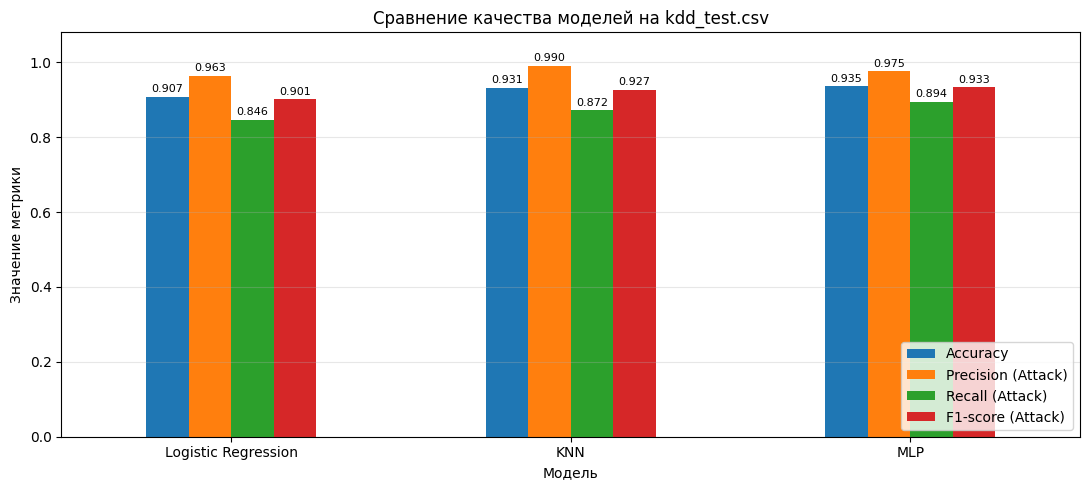

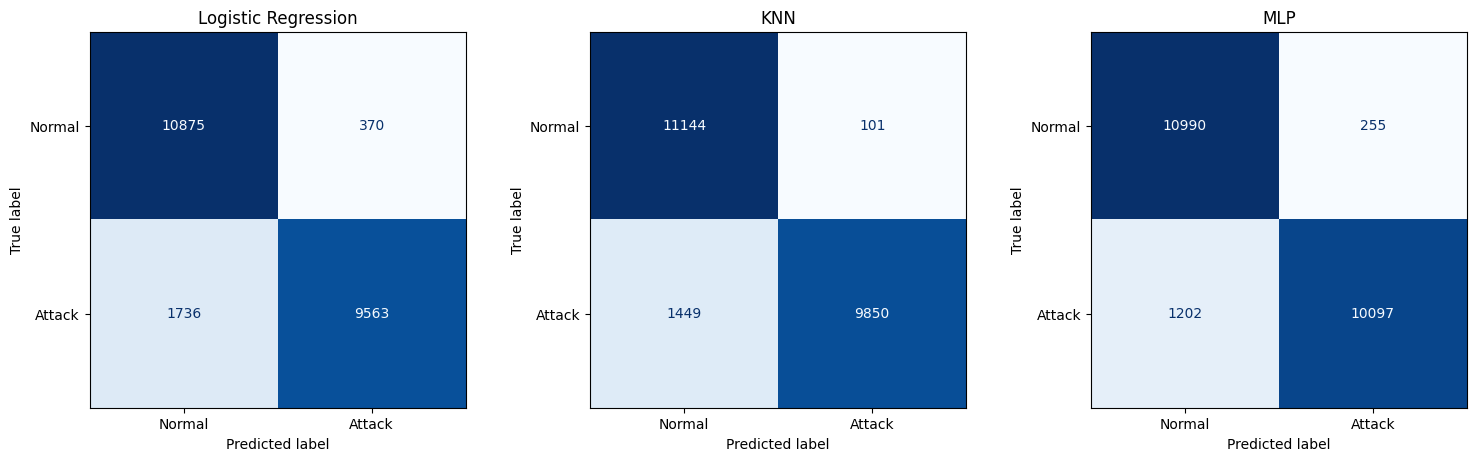

In [25]:
# 1. Сравнение основных метрик по моделям
metric_cols = ['Accuracy', 'Precision (Attack)', 'Recall (Attack)', 'F1-score (Attack)']
ax = df_test_comparison[metric_cols].plot(kind='bar', figsize=(11, 5), rot=0)
ax.set_ylim(0, 1.08)
ax.set_ylabel('Значение метрики')
ax.set_title('Сравнение качества моделей на kdd_test.csv')
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='lower right')

for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8, padding=2)

plt.tight_layout()
plt.savefig(processed_dir / 'models_metrics_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# 2. Матрицы ошибок для всех трёх моделей
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)

for ax, (model_name, cm) in zip(axes, confusion_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal', 'Attack'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(model_name)

fig.savefig(processed_dir / 'models_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

### Выводы по итогам экспериментов

1. На валидационной выборке проверены варианты масштабирования и основные гиперпараметры для всех трёх моделей.
2. На независимой выборке `kdd_test.csv` получены итоговые метрики `Accuracy`, `Precision`, `Recall`, `F1-score` (для класса `Attack`) и матрицы ошибок.
3. Выбранные конфигурации переносятся в скрипт `scripts/train_models.py` для воспроизводимого обучения и сохранения моделей в каталог `models/`.